In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def draw_levels(f, func_name, name, path, x_star, bounds=[-1.0, 1.0, -2.0, 1.0], x_true=None, levels=55, num=800):
    X1, X2 = np.meshgrid(np.linspace(bounds[0], bounds[1], num), np.linspace(bounds[2], bounds[3], num))
    Y = f([X1, X2])
    plt.figure(figsize=(8, 7))
    plt.contour(X1, X2, Y, levels=levels)
    plt.plot(path[:, 0], path[:, 1], 'o-', color='crimson', markersize=6, linewidth=1.5, label='траектория')
    plt.plot(path[0, 0], path[0, 1], 'o', markersize=10, label='x0')
    plt.plot(x_star[0], x_star[1], 'r*', markersize=18, label='x*')
    if x_true is not None:
        plt.plot(x_true[0], x_true[1], 'b*', markersize=18,
                 label='$x^*$ (точный)')
        plt.plot([x_star[0], x_true[0]], [x_star[1], x_true[1]],
                 'k--', linewidth=1, alpha=0.6)
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.title(name + ' ' +func_name)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [3]:
def f2(x):
    x1, x2 = x[0], x[1]
    return 2*x1**3 - x1*x2 + x2**2 - 2*x1 + 3*x2 - 4

def grad_f2(x):
    return np.array([6*x[0]**2 - x[1] - 2, -x[0] + 2*x[1] + 3])

In [4]:
def f5(x):
    x1, x2 = x[0], x[1]
    return (x2**2 + x1**2 - 1)**2 + (x1 + x2 - 1)**2

def grad_f5(x):
    r = x[0]**2 + x[1]**2 - 1
    s = x[0] + x[1] - 1
    return np.array([4*x[0]*r + 2*s, 4*x[1]*r + 2*s])

In [5]:
def dich(func, a0, b0, l=0.001, eps=0.00001):
    # start = time.time()
    a_k = a0
    b_k = b0
    k = 0
    while True:
        y_k = (a_k+b_k-eps)/2
        z_k = (a_k+b_k+eps)/2
        if func(y_k) <= func(z_k):
            a_next = a_k
            b_next = z_k
        else:
            a_next = y_k
            b_next = b_k
        L_next = abs(b_next-a_next)
        if L_next <= l:
            # end = time.time()
            # print(f'Execution time of dichotomy: {end - start} ms')
            return (a_next + b_next) / 2
        else:
            k += 1
            a_k = a_next
            b_k = b_next

In [6]:
def fix(f, x, t, i):
    temp = x.copy()
    temp[i] = t
    return f(temp)

def descent(f, x0=[0.0, 0.0], limit=1000, eps=0.00001, delta=1.0):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    for _ in range(limit):
        x_old = x.copy()
        for i in range(len(x)):
            g = lambda t, i=i: fix(f, x, t, i)
            x[i] = dich(g, x[i] - delta, x[i] + delta, l=eps*10, eps=eps)
        path.append(x.copy())
        if np.linalg.norm(x - x_old) < eps:
            break
    return x, f(x), np.array(path)

In [13]:
def davidon_and_co(f, grad, x0=[0.0, 0.0], eps=0.0001, limit=1000):
    x = np.array(x0, dtype=float)
    path = [x.copy()]
    H = np.eye(len(x))
    for _ in range(limit):
        g = grad(x)
        if np.linalg.norm(g) < eps:
            break
        p = np.dot(-H, g)
        second = lambda a: f(x + a * p)
        alpha = dich(second, 0.0, 1.0)
        s = alpha * p
        x_new = x + s
        y = grad(x_new) - g
        Hy = np.dot(H, y)
        H = H + np.outer(s, s) / np.dot(s, y) - np.outer(Hy, Hy) / np.dot(y, Hy)
        x = x_new
        path.append(x.copy())
    return x, f(x), np.array(path)

x2_star=[ 0.33330882 -1.33337606]
f2_star=-6.370370368390278


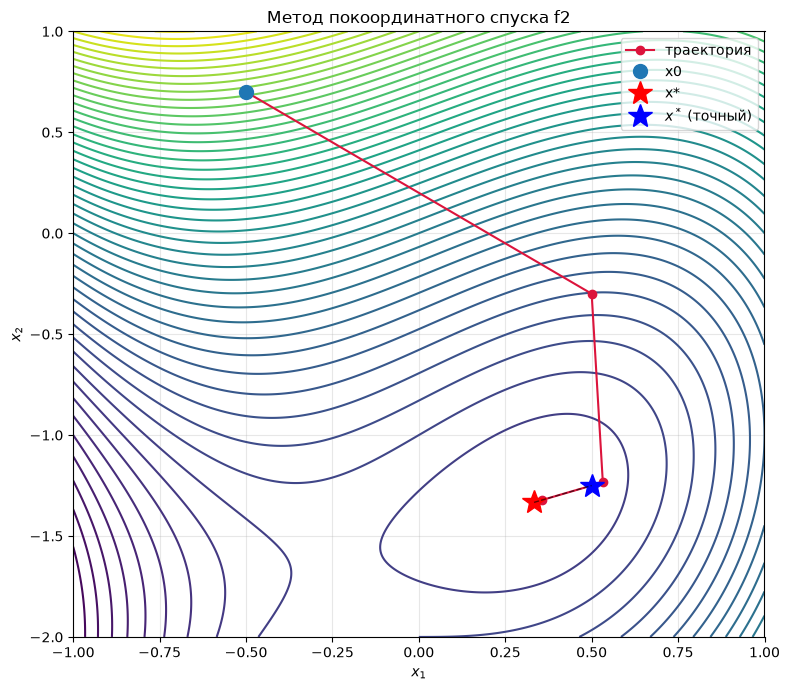

In [19]:
x2_star, f2_star, path2 = descent(f2, [-0.5, 0.7])
print(f'x2_star={x2_star}', f'f2_star={f2_star}', sep='\n')
draw_levels(f2, 'f2', 'Метод покоординатного спуска', path=path2, x_true=[1/2, -5/4], x_star=x2_star)

x51_star=[-1.70389148e-16  1.00001000e+00]
f51_star=5.000040000124413e-10


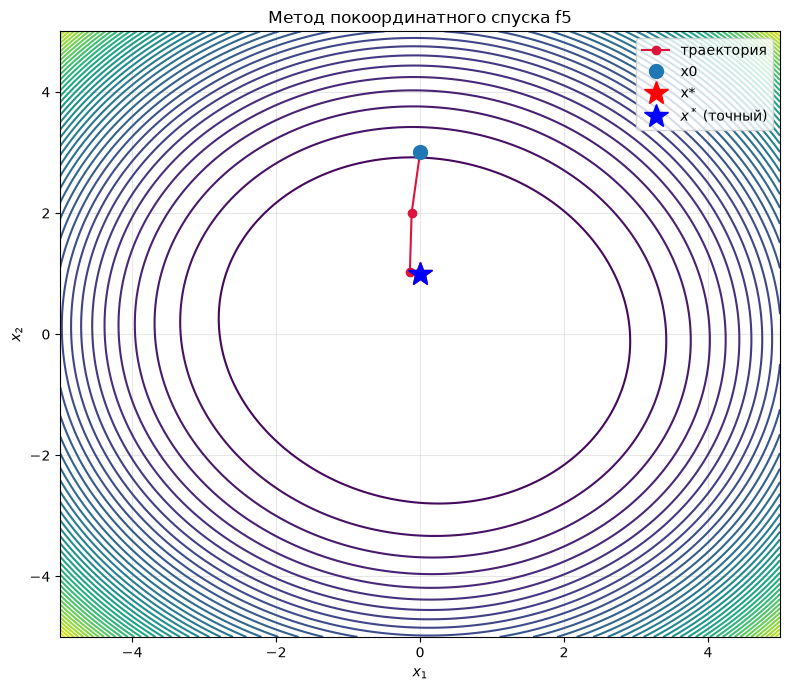

In [9]:
x_star51, f_star51, path51 = descent(f5, [0.0, 3.0])
print(f'x51_star={x_star51}', f'f51_star={f_star51}', sep='\n')
draw_levels(f5, 'f5', 'Метод покоординатного спуска', path=path51, bounds=[-5.0, 5.0, -5.0, 5.0], x_true=[0.0, 1.0], 
            x_star=x_star51, levels=42)

x52_star=[ 1.00001000e+00 -5.16554573e-17]
f52_star=5.000040000168822e-10


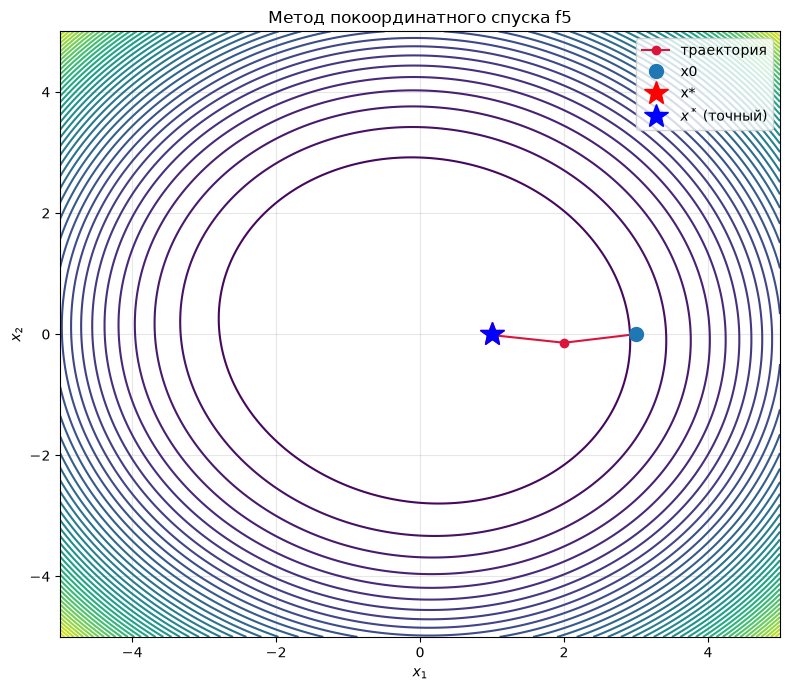

In [12]:
x_star52, f_star52, path52 = descent(f5, [3.0, 0.0])
print(f'x52_star={x_star52}', f'f52_star={f_star52}', sep='\n')
draw_levels(f5, 'f5', 'Метод покоординатного спуска', path=path52, bounds=[-5.0, 5.0, -5.0, 5.0], x_true=[1.0, 0.0], 
            x_star=x_star52, levels=42)

x22_star=[ 0.33334429 -1.33335871]
f22_star=-6.370370369208242


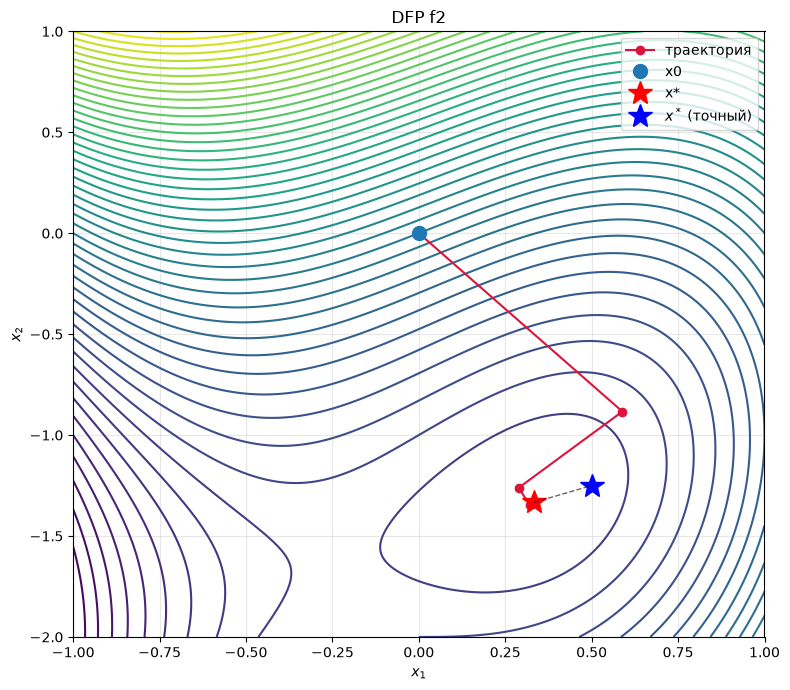

In [14]:
x_star22, f_star22, path22 = davidon_and_co(f2, grad_f2)
print(f'x22_star={x_star22}', f'f22_star={f_star22}', sep='\n')
draw_levels(f2, 'f2', 'DFP', path=path22, x_true=[1/2, -5/4], 
            x_star=x_star22)

x522_star=[9.99998990e-01 9.86874266e-06]
f522_star=8.255929534242416e-11


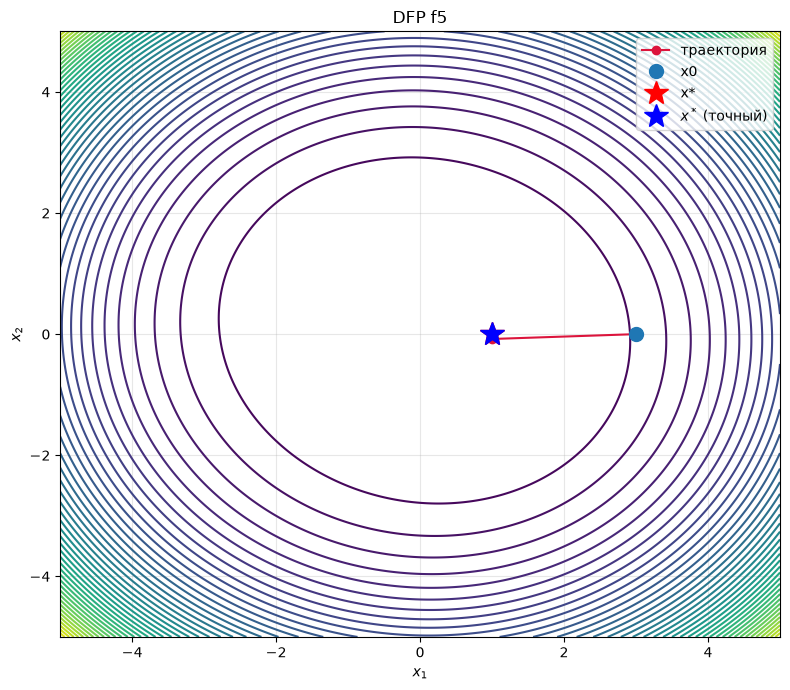

In [15]:
x_star522, f_star522, path522 = davidon_and_co(f5, grad_f5, x0=[3.0, 0.0])
print(f'x522_star={x_star522}', f'f522_star={f_star522}', sep='\n')
draw_levels(f5, 'f5', 'DFP', path=path522, bounds=[-5.0, 5.0, -5.0, 5.0], x_true=[1.0, 0.0], 
            x_star=x_star522, levels=42)

x512_star=[9.86874266e-06 9.99998990e-01]
f512_star=8.255929534242416e-11


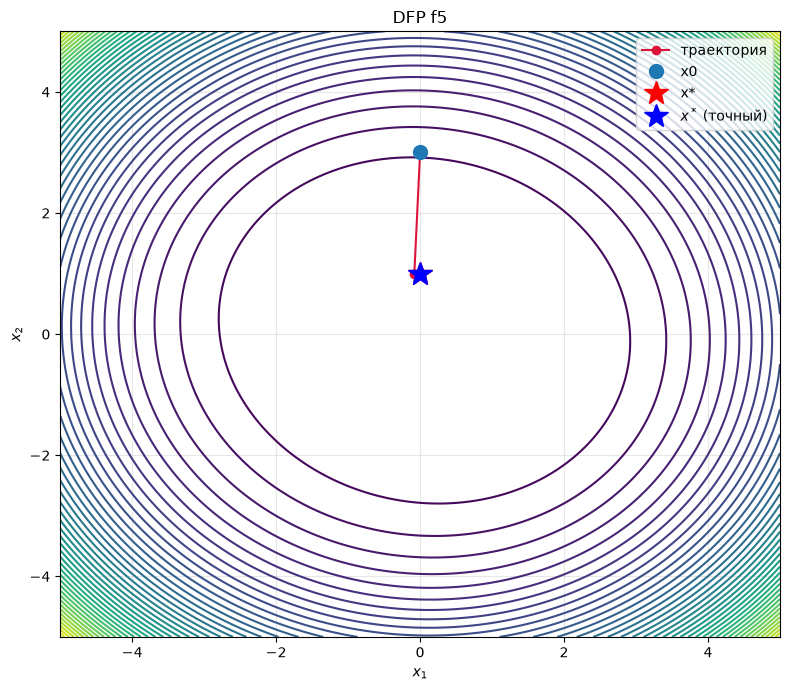

In [17]:
x_star512, f_star512, path512 = davidon_and_co(f5, grad_f5, x0=[0.0, 3.0])
print(f'x512_star={x_star512}', f'f512_star={f_star512}', sep='\n')
draw_levels(f5, 'f5', 'DFP', path=path512, bounds=[-5.0, 5.0, -5.0, 5.0], x_true=[0.0, 1.0], 
            x_star=x_star512, levels=42)
